# Lab 10C — Acoustic AI for Environment: Bird Species Classification (BirdNET)

**Authored by**: Seetha Parameswaran, BITS Pilani WILP

In health (10A) we had labelled classes and trained a classifier; in industry (10B) we had no fault labels and trained an anomaly detector. Environmental acoustics presents a third situation:
**thousands of possible species, most of them rare, and field recordings that carry only weak, file-level labels.** Training a classifier from scratch is infeasible here — so instead we stand on a large **pretrained model, BirdNET**, and run inference.

BirdNET is trained on 6000+ species. It slices each recording into 3-second windows and reports, per window, the species it believes are present along with a confidence. This demo runs BirdNET on field recordings from the **Western Ghats** (a global biodiversity hotspot), reads the predictions against the known species in each filename, and uses the results to expose three realities of environmental acoustics: **domain shift** (the model is only as good as its training distribution), the **long tail** (the rare species you most care about are the hardest to detect), and **weak, noisy labels** (a clip returns a *set* of guesses, not a clean answer).



## Learning Objectives

By the end of this lab you will be able to:

1. Run a **pretrained** audio model (BirdNET) for inference without any training
2. Interpret **per-window, multi-label** predictions with confidence scores
3. Apply **location and confidence priors** and understand how they filter predictions
4. Recognise **domain shift** — why a model succeeds on some species and fails on others
5. Explain the **long-tail** problem and why accuracy / micro-averaged metrics mislead
6. Understand **weak labels** and why pretrained output needs human verification

## Dataset

**Source:** [xeno-canto.org](https://xeno-canto.org) — a public archive of community-contributed wildlife sound recordings, free for research and education.

**This demo uses** 10 short recordings of Western Ghats bird species, downloaded individually from xeno-canto (each file named `XC<id>_-_<species>.mp3`, so the true species is embedded in the filename for checking predictions). Species include *House Sparrow*, *Malabar Grey Hornbill*, *Nilgiri Flowerpecker*, *Vernal Hanging-Parrot*, *Purple-rumped Sunbird*, and others.

**How to download your own set:**
- Browse or search a species at `https://xeno-canto.org`
- Download any recording directly via `https://xeno-canto.org/<ID>/download`
- 5–15 short clips is plenty for this demo; keep the species name in the filename

**Alternatives (larger, labelled):**
- **BirdCLEF** (Kaggle) — the annual bird-sound identification challenge dataset
- **Cornell Macaulay Library** — large curated archive

**BirdNET model:** downloaded automatically on the first `Analyzer()` call (needs internet once); runs on CPU thereafter. Install with `pip install birdnetlib`.



## 1. Setup

BirdNET runs on CPU. Install the analyzer package on the lab machine:
```
pip install birdnetlib
```
`birdnetlib` wraps the official BirdNET-Analyzer TFLite model — no GPU, no HF token.

Point `AUDIO_DIR` at a folder of a few field recordings (`.wav`/`.mp3`).
A small xeno-canto or BirdCLEF subset works well. `LAT`/`LON`/`WEEK` are optional
location/season priors BirdNET uses to down-weight implausible species.

In [1]:
import os, glob
import numpy as np

AUDIO_DIR = "/home/seetha/PythonScriptsCourses/PythonScriptsCourses/Audio Analysis/Data/birdclef_subset"   # <-- EDIT: folder of a few recordings
# Set the location prior. These are Western Ghats birds — give BirdNET the lat/lon
LAT, LON = 11.4, 76.7    # Nilgiris / Western Ghats
WEEK     = -1            # or set season if known
MIN_CONF = 0.1           # confidence floor for a detection

files = sorted(glob.glob(os.path.join(AUDIO_DIR, "*.wav")) +
               glob.glob(os.path.join(AUDIO_DIR, "*.mp3")) +
               glob.glob(os.path.join(AUDIO_DIR, "*.ogg")))
print("recordings found:", len(files))
for f in files[:8]:
    print("  ", os.path.basename(f))

recordings found: 10
   XC1036272_-_White-rumped_Munia.mp3
   XC191850_-_House_Sparrow.mp3
   XC284857_-_Purple-rumped_Sunbird.mp3
   XC369157_-_Pale-billed_Flowerpecker.mp3
   XC369290_-_Vernal_Hanging_Parrot.mp3
   XC369373_-_Malabar_Grey_Hornbill.mp3
   XC474074_-_Thick-billed_Flowerpecker.mp3
   XC498561_-_Malabar_Grey_Hornbill.mp3


## 2. Load the pretrained BirdNET model

BirdNET is trained on 6000+ species. That scale is the whole point: no classroom
dataset could cover this, so environmental acoustics leans on transfer from a
large pretrained model rather than training a fresh CNN.

!pip install birdnetlib

In [2]:
from birdnetlib import Recording
from birdnetlib.analyzer import Analyzer

analyzer = Analyzer()          # downloads/loads the pretrained BirdNET TFLite model
print("BirdNET labels available:", len(analyzer.labels))
print("example labels:", analyzer.labels[:3], "...")

load model
Model loaded.
Labels loaded.
Labels loaded.
load_species_list_model
Meta model loaded.
BirdNET labels available: 3337
example labels: ['Abroscopus albogularis_Rufous-faced Warbler', 'Abroscopus superciliaris_Yellow-bellied Warbler', 'Aburria aburri_Wattled Guan'] ...


INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


## 3. Run inference on one recording

BirdNET slices the audio into **3-second windows** and emits, for each window, the
species it thinks are present with a confidence. Note this is inherently
**multi-label over time** — several species can co-occur, and the answer is
"who is present *when*", not one label for the whole file.

In [3]:
def analyze(path):
    kwargs = dict(analyzer=analyzer, min_conf=MIN_CONF)
    if LAT is not None and LON is not None:
        kwargs.update(lat=LAT, lon=LON)
    if WEEK and WEEK > 0:
        kwargs.update(week_48=WEEK)
    rec = Recording(path=path, **kwargs)
    rec.analyze()
    return rec.detections   # list of dicts: common_name, scientific_name, start_time, end_time, confidence

dets = analyze(files[0])
print(f"{os.path.basename(files[0])}: {len(dets)} detections\n")
for d in dets[:12]:
    print(f"  [{d['start_time']:5.1f}-{d['end_time']:5.1f}s]  "
          f"{d['common_name']:<28} conf={d['confidence']:.2f}")

read_audio_data
read_audio_data: complete, read  13 chunks.
analyze_recording /home/seetha/PythonScriptsCourses/PythonScriptsCourses/Audio Analysis/Data/birdclef_subset/XC1036272_-_White-rumped_Munia.mp3
recording has lon/lat
set_predicted_species_list_from_position
return_predicted_species_list
-1
169 species loaded.
XC1036272_-_White-rumped_Munia.mp3: 7 detections

  [  3.0-  6.0s]  Indian Gray Hornbill         conf=0.10
  [  9.0- 12.0s]  Indian Gray Hornbill         conf=0.19
  [ 15.0- 18.0s]  Indian Gray Hornbill         conf=0.10
  [ 27.0- 30.0s]  White-throated Kingfisher    conf=0.17
  [ 27.0- 30.0s]  Indian Gray Hornbill         conf=0.15
  [ 30.0- 33.0s]  White-throated Kingfisher    conf=0.11
  [ 33.0- 36.0s]  Southern Hill Myna           conf=0.24


## 4. Aggregate across the folder — see the long tail

Collect detections over all recordings and count species. In any real deployment
a few species dominate and a long tail appears only once or twice — which is exactly
why accuracy and micro-averaged metrics mislead: they are driven by the common species,
while the ecologist usually cares about the rare one.

In [4]:
import os, re
from collections import Counter


# run analysis ONCE, store results (logs print here, once)
results = {f: analyze(f) for f in files}

def true_species(fname):
    # "XC369373_-_Malabar_Grey_Hornbill.mp3" -> "malabar grey hornbill"
    stem = os.path.basename(fname).rsplit(".", 1)[0]
    name = stem.split("_-_")[-1].replace("_", " ")
    return name.lower()

def norm(s):
    # unify spelling: grey/gray, hyphens, spaces
    return re.sub(r"[\s\-]+", " ", s.lower()).replace("gray", "grey").strip()

rows = []
for f in files:
    dets = results[f]
    truth = true_species(f)
    if dets:
        # best-confidence prediction for this file
        best = max(dets, key=lambda d: d["confidence"])
        pred, conf = best["common_name"], best["confidence"]
        correct = norm(truth) in norm(pred) or norm(pred) in norm(truth)
    else:
        pred, conf, correct = "— none —", 0.0, False
    rows.append((truth.title(), pred, conf, correct, len(dets)))

species_counter = Counter()
for f in files:
    for d in results[f]:
        species_counter[d["common_name"]] += 1

# ---- neat table ----
print(f"{'True species':<26}{'Top prediction':<26}{'Conf':>6}  {'Result':<8}{'#det':>4}")
print("-" * 74)
for truth, pred, conf, correct, ndet in rows:
    mark = "CORRECT" if correct else "WRONG"
    print(f"{truth:<26}{pred:<26}{conf:>6.2f}  {mark:<8}{ndet:>4}")

n_ok = sum(r[3] for r in rows)
print("-" * 74)
print(f"Correctly identified: {n_ok}/{len(rows)} files")

# ---- long tail: how often each species is the TOP guess ----
print("\nLong-tail view (species as top prediction, across files):")
top_counts = Counter(r[1] for r in rows)
for sp, n in top_counts.most_common():
    bar = "#" * n
    print(f"  {sp:<26}{bar} ({n})")
singletons = [sp for sp, n in top_counts.items() if n == 1]
print(f"\nSpecies appearing as top guess only once (the long tail): {len(singletons)}")

read_audio_data
read_audio_data: complete, read  13 chunks.
analyze_recording /home/seetha/PythonScriptsCourses/PythonScriptsCourses/Audio Analysis/Data/birdclef_subset/XC1036272_-_White-rumped_Munia.mp3
recording has lon/lat
set_predicted_species_list_from_position
read_audio_data
read_audio_data: complete, read  9 chunks.
analyze_recording /home/seetha/PythonScriptsCourses/PythonScriptsCourses/Audio Analysis/Data/birdclef_subset/XC191850_-_House_Sparrow.mp3
recording has lon/lat
set_predicted_species_list_from_position
read_audio_data
read_audio_data: complete, read  8 chunks.
analyze_recording /home/seetha/PythonScriptsCourses/PythonScriptsCourses/Audio Analysis/Data/birdclef_subset/XC284857_-_Purple-rumped_Sunbird.mp3
recording has lon/lat
set_predicted_species_list_from_position
read_audio_data
read_audio_data: complete, read  7 chunks.
analyze_recording /home/seetha/PythonScriptsCourses/PythonScriptsCourses/Audio Analysis/Data/birdclef_subset/XC369157_-_Pale-billed_Flowerpecker.m

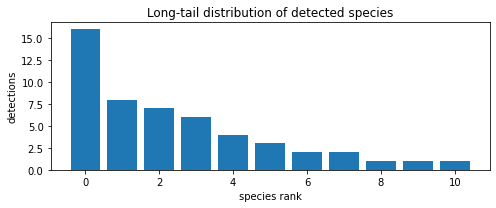

In [5]:
import matplotlib.pyplot as plt
from collections import Counter


counts = sorted(species_counter.values(), reverse=True)
plt.figure(figsize=(7,3))
plt.bar(range(len(counts)), counts)
plt.xlabel("species rank"); plt.ylabel("detections")
plt.title("Long-tail distribution of detected species")
plt.tight_layout(); plt.show()

## 5. Weak labels: what we *don't* have

Field-recording datasets typically ship a **file-level** label ("this species is
present somewhere in the 10-minute clip") with **no onset/offset times**. BirdNET
gives us fine time localisation for free, but if we wanted to *train*, the weak
labels would force multiple-instance learning (chunk the clip, pool over chunks
with attention/max) rather than ordinary per-window supervision.

In [9]:
# Illustrative: reduce BirdNET's per-window detections to a single weak file label,
# i.e. the presence set — mimicking what a raw field dataset would actually give you.
def weak_label(path):
    return sorted({d["common_name"] for d in analyze(path)})

import re

def _norm(s):
    return re.sub(r"[\s\-]+", " ", s.lower()).replace("gray", "grey").strip()

def _truth(fname):
    return os.path.basename(fname).rsplit(".", 1)[0].split("_-_")[-1].replace("_", " ")

table = [(_truth(f), weak_label(f)) for f in files[:5]]


print(f"\n{'True species (filename)':<26}{'Verdict':<8}{'BirdNET present set'}")
print("-" * 90)
for truth, present in table:
    hit = any(_norm(truth) in _norm(p) or _norm(p) in _norm(truth) for p in present)
    print(f"{truth:<26}{('FOUND' if hit else 'MISS'):<8}{', '.join(present)}")

read_audio_data
read_audio_data: complete, read  13 chunks.
analyze_recording /home/seetha/PythonScriptsCourses/PythonScriptsCourses/Audio Analysis/Data/birdclef_subset/XC1036272_-_White-rumped_Munia.mp3
recording has lon/lat
set_predicted_species_list_from_position
read_audio_data
read_audio_data: complete, read  9 chunks.
analyze_recording /home/seetha/PythonScriptsCourses/PythonScriptsCourses/Audio Analysis/Data/birdclef_subset/XC191850_-_House_Sparrow.mp3
recording has lon/lat
set_predicted_species_list_from_position
read_audio_data
read_audio_data: complete, read  8 chunks.
analyze_recording /home/seetha/PythonScriptsCourses/PythonScriptsCourses/Audio Analysis/Data/birdclef_subset/XC284857_-_Purple-rumped_Sunbird.mp3
recording has lon/lat
set_predicted_species_list_from_position
read_audio_data
read_audio_data: complete, read  7 chunks.
analyze_recording /home/seetha/PythonScriptsCourses/PythonScriptsCourses/Audio Analysis/Data/birdclef_subset/XC369157_-_Pale-billed_Flowerpecker.m

## Takeaways

Running one pretrained model across ten Western Ghats recordings produced a clear spectrum of outcomes:

- **Clean hits** — *House Sparrow*, *Pale-billed Flowerpecker*. Species well represented in BirdNET's   training data are identified confidently and correctly.
- **Noisy hits** — *Vernal Hanging-Parrot*. The correct species is found, but buried among several   spurious detections; the file-level "present" set is right but not trustworthy on its own.
- **Misses** — *White-rumped Munia*, *Purple-rumped Sunbird*. Under-represented species are not named   at all; the model substitutes low-confidence guesses from species it *does* know   (Hornbill, Kingfisher, Cinereous Tit).

**The real lesson is not "endemic species fail."** *Malabar Grey Hornbill* — also endemic — is detected well, because BirdNET has seen enough of it. What determines success is **how much of a species sits in the training distribution**, not geography alone. This is domain shift in practice.

**Consequences for how we build and evaluate environmental acoustic systems:**

- **Task:** pretrained inference / transfer — training from scratch at 6000-species scale is not an option.
- **Output:** multi-label over time — several species co-occur; predictions are per 3-second window, not   one label per file.
- **Long tail:** a few species dominate the detections, many appear once. Accuracy and micro-averaged   metrics are driven by the common species and hide the rare ones — report **mAP** and **macro-F1** instead.
- **Weak labels:** a clip yields a noisy *set* of species. BirdNET's output cannot be taken as ground truth;   confidence thresholds and human verification are essential.

**Module wrap (A / B / C):** one framework, three different problems — labelled classes → classify (health), unlabelled faults → detect anomalies (industry), thousands of weakly-labelled classes → stand on a pretrained model (environment). The feature pipeline barely changed across all three; correctly identifying *which problem you actually have* did all the work.